# Support Vector Machine on Image Features

### Author
   * Jonathan Sancho Loaiza

### Running this notebook

It runs unchanged in Google Colab and in a local Jupyter installation. Every
library it uses, numpy, pandas, pillow, scikit-image, scikit-learn, matplotlib,
seaborn and joblib, is already installed in Colab, so there is nothing to
`pip install`.

The notebook fetches its own data. The first cell of the data understanding
section looks for the folder `Mascarilla` next to the notebook, and only when
that folder is missing does it download `mascarilla.zip` from the course GitLab
repository and unpack it. If the folder or the zip is already there the download
is skipped, so running the notebook a second time costs nothing.

Run the cells in order with Runtime and Run all. The feature extraction cell is
the slow one, a couple of minutes on the whole dataset, and it writes its result
to a file so that a later run reads it back instead of repeating the work.

## Problem Analysis (CRISP-DM 1: Business Understanding)

The task is to look at a photograph of a face and answer whether the person is
wearing a mask. It is the check a camera at the door of a hospital or a
supermarket had to make thousands of times a day during the pandemic, and it is
the kind of decision a person makes in a glance and cannot explain in a rule.

What makes it a machine learning problem rather than a programming one is that
there is no measurement of an image that says mask. A mask can be blue, white,
black, printed with a pattern or made of cloth, it can cover more or less of the
face, and the photograph can be taken from any angle and under any light. What
the two classes really differ in is a texture and a shape: a face without a mask
has a nose and a mouth, which are edges arranged in a way the camera sees over
and over again, and a face with a mask has a smooth surface in the lower half
with a hard border running across the cheeks.

A Support Vector Machine does not read pixels. It reads a row of numbers per
observation and separates the two classes with the widest possible corridor
between them, so the whole difficulty of this notebook is turning a photograph
into a row of numbers that keeps what distinguishes the two classes and drops
what does not. The description used here has two halves. The first is the
histogram of oriented gradients, written HOG, which measures in which direction
the brightness changes at each small square of the image, so it records the edges
of the face without recording the identity of the person. The second is a set of
colour histograms, which record what colours the image contains and how the
lower half of the picture compares with the upper half, since a mask is usually a
flat area of one colour placed exactly there.

The response is a single yes or no, so this is a binary classification. The class
counted as positive throughout the notebook is the face wearing a mask, which
means that recall answers the question a door camera cares about the least and
that specificity answers the one it cares about the most. Letting an uncovered
face pass as covered is the expensive mistake, and the evaluation section reads
the confusion matrix with that asymmetry in mind.

### Libraries

In [1]:
# Files and dataset download
import os
import time
import zipfile
import urllib.request

# Data handling
import numpy as np
import pandas as pd

# Images and visual features
from PIL import Image
from skimage.feature import hog
from skimage.color import rgb2gray, rgb2hsv

# Plots
import matplotlib.pyplot as plt
import seaborn as sns

# Model
from sklearn.svm import SVC, LinearSVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA

# Split and validation
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_val_score, cross_validate)

# Evaluation
from sklearn.metrics import (accuracy_score, f1_score, confusion_matrix,
                             classification_report, roc_curve, roc_auc_score)

# Saving the trained model
import joblib

# Where the data comes from and where it lands
DATASET_URL = ('https://gitlab.com/ejimenez/mascarilla/-/raw/main/'
               'mascarilla.zip?inline=false')
ZIP_NAME = 'mascarilla.zip'
DATA_DIR = 'Mascarilla'

# The two folders of the dataset and the code each one gets. The positive class,
# the one every recall and every ROC curve below refers to, is the face wearing a
# mask
CLASS_FOLDERS = {'without_mask': 0, 'with_mask': 1}
CLASS_NAMES = {0: 'without mask', 1: 'with mask'}

# Every image is brought to this size before any feature is computed
IMAGE_SIZE = (64, 64)

# HOG settings
ORIENTATIONS = 9
PIXELS_PER_CELL = (8, 8)
CELLS_PER_BLOCK = (2, 2)

# Colour settings
COLOR_BINS = 16

# Fixed so every run of the notebook gives the same split and the same model
RANDOM_STATE = 42

# Cache of the extracted features, so a second run does not repeat the work
FEATURE_CACHE = 'mask_features_%dpx.npz' % IMAGE_SIZE[0]

sns.set_style('whitegrid')
print('Libraries loaded.')

Libraries loaded.


## Data Understanding (CRISP-DM 2)

The dataset is the mask collection published in the course GitLab repository, a
zip file of about 170 megabytes holding two folders of photographs. The folder
name is the label: every file inside `with_mask` shows a covered face and every
file inside `without_mask` shows an uncovered one, so there is no separate
annotation file to join and no missing label to worry about.

In [2]:
# The dataset is fetched only when it is not already on disk. If the folder is
# there the cell does nothing, if only the zip is there it is unpacked, and if
# neither exists the zip is downloaded first
if os.path.isdir(DATA_DIR):
    print('The folder', DATA_DIR, 'is already present, nothing is downloaded.')
else:
    if os.path.exists(ZIP_NAME):
        print('The zip is already here, only unpacking is needed.')
    else:
        print('Downloading the dataset, this takes a moment...')
        start = time.time()
        urllib.request.urlretrieve(DATASET_URL, ZIP_NAME)
        print('Downloaded %.1f MB in %.1f seconds.'
              % (os.path.getsize(ZIP_NAME) / 1024 ** 2, time.time() - start))
    with zipfile.ZipFile(ZIP_NAME) as archive:
        archive.extractall('.')
    print('Unpacked into', DATA_DIR)

# What the dataset folder contains
print('Folders inside', DATA_DIR + ':', sorted(os.listdir(DATA_DIR)))

Downloaded 163.1 MB in 2.4 seconds.
Unpacked into Mascarilla
Folders inside Mascarilla: ['with_mask', 'without_mask']


The cell reports what it did. On the first run it downloads and unpacks, and on
any later run it finds the folder and does nothing, which is the behaviour that
makes the notebook safe to rerun. The listing confirms the two folders that carry
the labels.

Images in total: 7553

              Images  Share %
folder                       
with_mask       3725     49.3
without_mask    3828     50.7


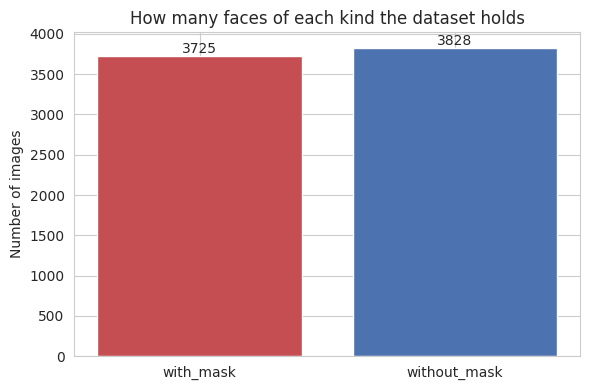

In [3]:
# The list of files of each class, with the label each folder gives
records = []
for folder, label in CLASS_FOLDERS.items():
    folder_path = os.path.join(DATA_DIR, folder)
    for name in sorted(os.listdir(folder_path)):
        if name.lower().endswith(('.jpg', '.jpeg', '.png')):
            records.append({'path': os.path.join(folder_path, name),
                            'folder': folder,
                            'label': label})

mask = pd.DataFrame(records)
print('Images in total:', len(mask))
print()
counts = mask['folder'].value_counts().sort_index()
share = (mask['folder'].value_counts(normalize=True).sort_index() * 100).round(1)
print(pd.DataFrame({'Images': counts.values, 'Share %': share.values},
                   index=counts.index))

plt.figure(figsize=(6, 4))
bars = plt.bar(counts.index, counts.values, color=['#c44e52', '#4c72b0'])
for bar, value in zip(bars, counts.values):
    plt.text(bar.get_x() + bar.get_width() / 2, value + 40, str(value), ha='center')
plt.ylabel('Number of images')
plt.title('How many faces of each kind the dataset holds')
plt.tight_layout()
plt.show()

The table and the bar chart count the files of each class. There are 7553
photographs, 3828 without a mask and 3725 with one, which is 50.7 against 49.3
percent.

That balance is worth stating plainly because it sets the floor of the
evaluation. A model that answered without a mask to every photograph, without
looking at a single pixel, would be right about half the time, so any accuracy
near 0.50 means the model learned nothing. It also means accuracy is a fair
summary here, which is not true of every dataset: when one class holds ninety
percent of the rows accuracy hides the failure on the small class, but with an
almost even split accuracy and the per class figures tell the same story.

The balance has a second consequence for this particular model. An SVM is fitted
by trading the width of the corridor between the classes against the penalty for
the observations that fall on the wrong side, and when one class is much larger
its errors dominate that penalty and the boundary drifts towards the small class.
Here the two classes weigh the same, so no correction of the class weights is
needed and the model is fitted on the data as it is.

        width  height      pixels
count  7553.0  7553.0      7553.0
mean    259.6   268.9    133563.6
std     274.9   257.7    731574.0
min      26.0    37.0       962.0
25%     150.0   144.0     20860.0
50%     204.0   225.0     50336.0
75%     275.0   275.0     50625.0
max    5760.0  5412.0  25620408.0


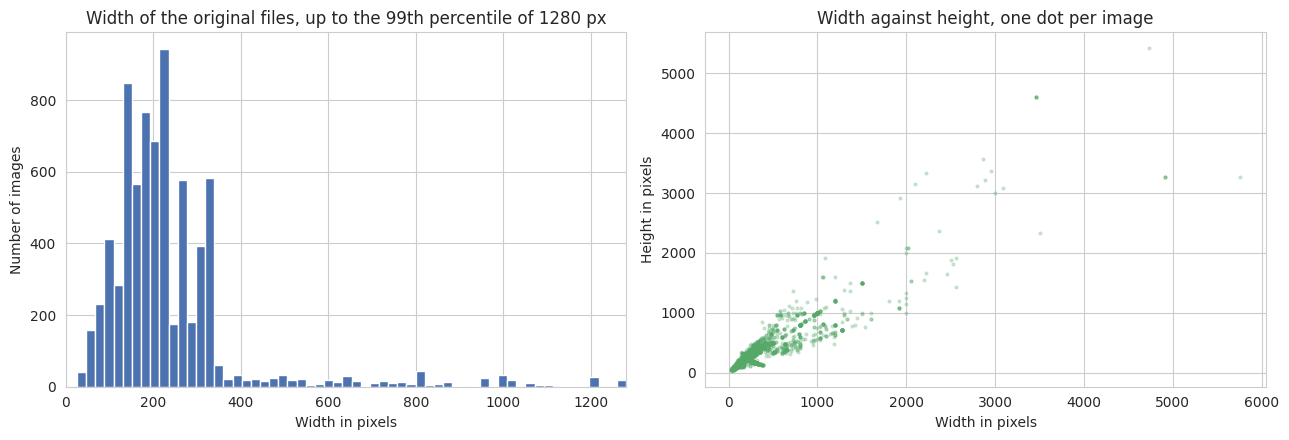

Images wider than 1280 pixels, left out of the histogram: 72 of 7553
The widest file is 5760 pixels across.

Colour modes across all 7553 files: {'RGB': 7544, 'RGBA': 5, 'P': 4}
Files that are not RGB: 9


In [4]:
# The size and the colour mode of every file, read from the header without
# decoding the pixels. Both come from the same open, so checking all 7553 files
# costs nothing over checking a sample of them
widths, heights, modes = [], [], []
for path in mask['path']:
    with Image.open(path) as handle:
        width, height = handle.size
        modes.append(handle.mode)
    widths.append(width)
    heights.append(height)

mask['width'] = widths
mask['height'] = heights
mask['pixels'] = mask['width'] * mask['height']
print(mask[['width', 'height', 'pixels']].describe().round(1))

# The few enormous files stretch the width axis so far that every bar is squeezed
# against the left edge, so the histogram is drawn up to the 99th percentile and
# the images left out of it are counted underneath rather than hidden
width_cut = float(mask['width'].quantile(0.99))
beyond = int((mask['width'] > width_cut).sum())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(mask['width'], bins=60, range=(mask['width'].min(), width_cut),
             color='#4c72b0')
axes[0].set_xlim(0, width_cut)
axes[0].set_xlabel('Width in pixels')
axes[0].set_ylabel('Number of images')
axes[0].set_title('Width of the original files, up to the 99th percentile of %d px'
                  % round(width_cut))
axes[1].scatter(mask['width'], mask['height'], s=4, alpha=0.25, color='#55a868')
axes[1].set_xlabel('Width in pixels')
axes[1].set_ylabel('Height in pixels')
axes[1].set_title('Width against height, one dot per image')
plt.tight_layout()
plt.show()

# What the histogram leaves out, so the cut hides nothing
print('Images wider than %d pixels, left out of the histogram: %d of %d'
      % (round(width_cut), beyond, len(mask)))
print('The widest file is', int(mask['width'].max()), 'pixels across.')

# Which files are not plain three channel images, counted over the whole dataset
print()
print('Colour modes across all', len(mask), 'files:',
      pd.Series(modes).value_counts().to_dict())
print('Files that are not RGB:', int((pd.Series(modes) != 'RGB').sum()))

The table summarises the size of the original files and the two plots show it. The
histogram on the left counts how many images have each width, and the scatter on
the right puts one dot per image at its width and its height, so a dot on the
diagonal is a square photograph and a dot far off it is a wide or a tall one.

The files are not of one size and the range is wide. Half of them fall between 150
and 275 pixels across with a median of 204 by 225, while the smallest is 26 by 37
and the largest 5760 by 5412, which is twenty five million pixels against nine
hundred.

The two panels are drawn on different ranges because of those extremes. Over the
full width every bar of the histogram would sit in the leftmost eighth of the axis
with the rest blank, so it is cut at the ninety ninth percentile of 1280 pixels and
the 72 images of 7553 that fall beyond it are counted underneath rather than
hidden. The scatter keeps the whole range, where the outliers are worth seeing: a
dense cloud near the origin, a diagonal of square photographs and a few very large
files far from the rest.

This decides the first preparation step. A Support Vector Machine needs every
observation to be a row of the same length, and a description computed on a larger
picture produces more numbers than the same description computed on a smaller one,
so the images have to be brought to a common size before anything is measured. The
size chosen below is 64 by 64, which is small enough that describing seven thousand
images takes about a minute and large enough that a nose, a mouth and the border of
a mask still occupy several pixels each. The scatter also names the cost of that
choice: the photographs off the diagonal are not square, so forcing them into a
square frame stretches the face.

The colour mode comes from the same file headers, so the count covers all 7553
files. Nine of them are not plain three channel RGB, five with an alpha channel and
four written as a palette, and those are the files that would otherwise produce a
row of the wrong length. The `convert('RGB')` inside the loading function handles
them, which is also why the extraction cell prints a warning from the imaging
library about a palette image with transparency.

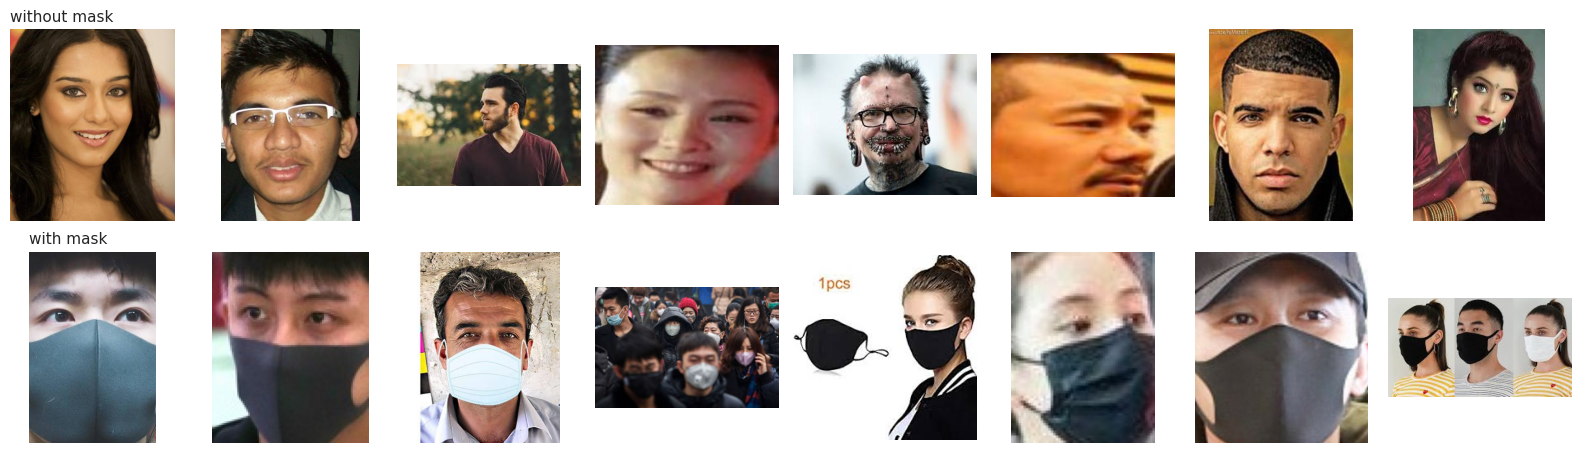

In [5]:
# Eight faces of each class, straight from the files
fig, axes = plt.subplots(2, 8, figsize=(16, 4.6))
for row, folder in enumerate(['without_mask', 'with_mask']):
    chosen = mask[mask['folder'] == folder].sample(8, random_state=RANDOM_STATE)
    for ax, path in zip(axes[row], chosen['path']):
        with Image.open(path) as handle:
            ax.imshow(handle.convert('RGB'))
        ax.axis('off')
    axes[row][0].set_title(folder.replace('_', ' '), loc='left', fontsize=11)
plt.tight_layout()
plt.show()

The grid shows eight photographs of each class as they come out of the files, the
uncovered faces on the top row and the covered ones below.

Two things about the collection are visible here and both matter later. The
photographs are not standardised: the faces are at different distances, at
different angles, against different backgrounds and under different light, and
several images include shoulders or a second person. And the masks themselves
vary in colour and shape, so the model cannot learn one particular blue and be
done.

What repeats in the lower row is not a colour but a place. In almost every
covered face the region under the eyes is a smooth surface with a border running
across it, and in the upper row that same region shows the edges of a nose and a
mouth. That is the regularity the shape half of the description is built to
capture, and the reason the colour half measures the two halves of the picture
separately rather than the picture as a whole.

## Data Exploration (CRISP-DM 2) and Data Preparation (CRISP-DM 3)

This section builds the row of numbers that stands for a photograph, and looks at
the data through it. Everything the model will ever know about an image is in
that row, so what the exploration has to establish is whether the two classes
actually differ in the quantities being measured.

In [6]:
# One image becomes a square of numbers between 0 and 1, so that every later
# step reads pictures of the same shape whatever the original file measured
def load_image(path):
    """Read a file as an RGB array of IMAGE_SIZE, scaled to the range 0 to 1."""
    with Image.open(path) as handle:
        resized = handle.convert('RGB').resize(IMAGE_SIZE, Image.BILINEAR)
    return np.asarray(resized, dtype=np.float32) / 255.0


# The shape half of the description: where the edges of the picture point
def hog_features(image, visualise=False):
    """Histogram of oriented gradients of the grey version of the image."""
    return hog(rgb2gray(image),
               orientations=ORIENTATIONS,
               pixels_per_cell=PIXELS_PER_CELL,
               cells_per_block=CELLS_PER_BLOCK,
               block_norm='L2-Hys',
               feature_vector=not visualise,
               visualize=visualise)


# The colour half: how the colours are spread and how the lower half of the
# picture, where a mask sits, compares with the upper half, where it does not
def color_features(image):
    """Colour histograms in HSV plus the mean colour of each half of the image."""
    hsv = rgb2hsv(image)
    blocks = []
    for channel in range(3):
        counts, _ = np.histogram(hsv[:, :, channel], bins=COLOR_BINS, range=(0.0, 1.0))
        blocks.append(counts / counts.sum())
    half = image.shape[0] // 2
    upper = image[:half].reshape(-1, 3).mean(axis=0)
    lower = image[half:].reshape(-1, 3).mean(axis=0)
    blocks.append(upper)
    blocks.append(lower)
    blocks.append(lower - upper)
    return np.concatenate(blocks)


def describe_image(image):
    """The full description of one image: shape first, then colour."""
    return np.concatenate([hog_features(image), color_features(image)])


# How long each half of the description is, measured on a real image
example = load_image(mask['path'].iloc[0])
HOG_LENGTH = len(hog_features(example))
COLOR_LENGTH = len(color_features(example))
print('Numbers produced by the shape half:', HOG_LENGTH)
print('Numbers produced by the colour half:', COLOR_LENGTH)
print('Numbers describing one image:', HOG_LENGTH + COLOR_LENGTH)

Numbers produced by the shape half: 1764
Numbers produced by the colour half: 57
Numbers describing one image: 1821


The three functions are the whole preparation, and the printed lengths say how
much of the description each half contributes.

The shape half is the histogram of oriented gradients. The image is turned to
grey, cut into squares of 8 by 8 pixels, and inside each square the direction in
which the brightness changes is measured at every pixel and collected into nine
bins covering the half circle from 0 to 180 degrees. So each square becomes nine
numbers saying how much of its edge content runs horizontally, diagonally or
vertically. Those squares are then grouped in blocks of 2 by 2 and each block is
normalised on its own, which is what makes the description survive a change of
light: doubling the brightness of a photograph doubles the size of every gradient
in a block and leaves their proportions, which is what the block keeps, untouched.

The colour half is three histograms of 16 bins computed on the HSV version of the
image, which describes a pixel by its hue, meaning which colour it is, its
saturation, meaning how strong that colour is against grey, and its value,
meaning how bright it is. HSV is used rather than RGB because a mask keeps its
hue under weak and strong light while its red, green and blue values all move
together, so the separation the model needs survives better in this coordinate
system. To those 48 numbers the function adds the mean red, green and blue of the
upper half of the picture, the same three for the lower half, and the difference
between them, which is the one measurement in the whole description that was
designed with the specific problem in mind.

Together they give a row of 1821 numbers per image, dominated by the shape half.
That imbalance in length is the reason the model comparison later fits the two
halves separately before fitting them together, since a block that is thirty
times longer than the other could carry the result on its own.

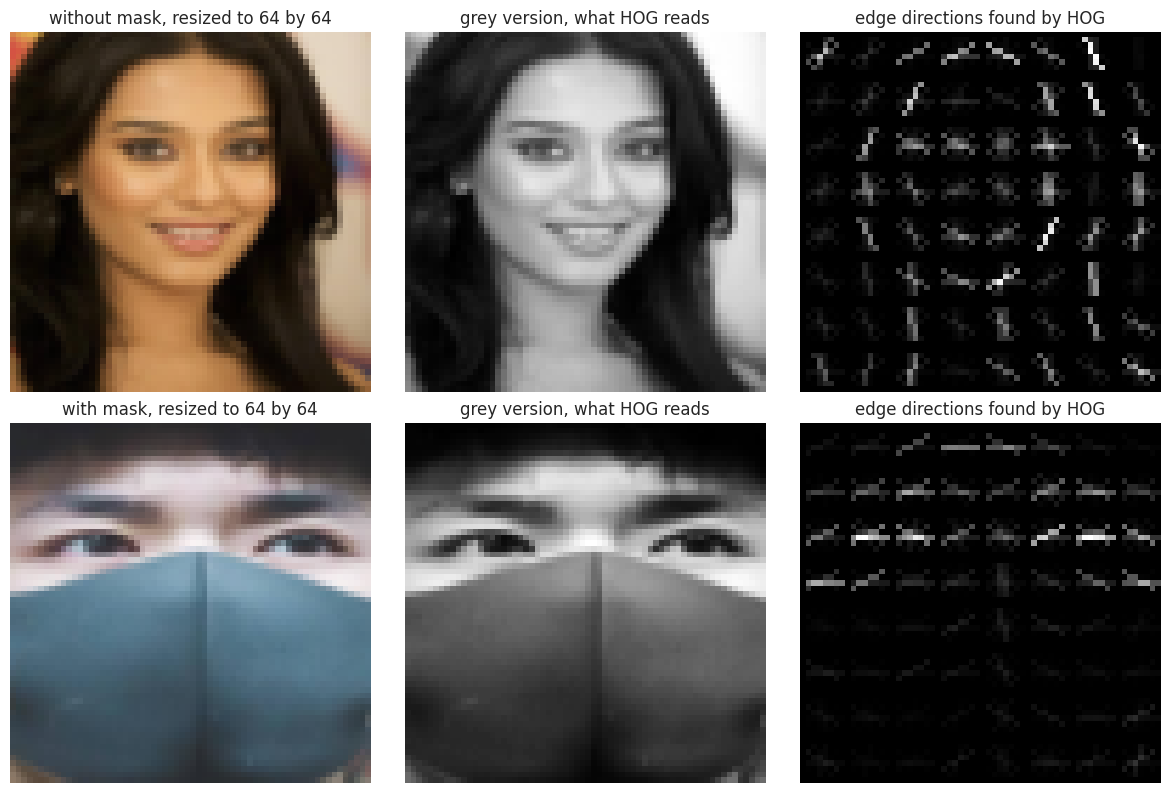

In [7]:
# The same picture as the model sees it: the resized image, its grey version and
# the edge directions HOG measures
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for row, folder in enumerate(['without_mask', 'with_mask']):
    path = mask[mask['folder'] == folder].sample(1, random_state=RANDOM_STATE).iloc[0]['path']
    image = load_image(path)
    _, drawing = hog_features(image, visualise=True)
    axes[row][0].imshow(image)
    axes[row][0].set_title(folder.replace('_', ' ') + ', resized to 64 by 64')
    axes[row][1].imshow(rgb2gray(image), cmap='gray')
    axes[row][1].set_title('grey version, what HOG reads')
    axes[row][2].imshow(drawing, cmap='gray')
    axes[row][2].set_title('edge directions found by HOG')
    for ax in axes[row]:
        ax.axis('off')
plt.tight_layout()
plt.show()

Each row is one photograph seen three ways. On the left is the image after the
resize, which is exactly what the description reads and already much coarser than
the original file. In the middle is its grey version, since HOG ignores colour
altogether. On the right is the drawing of the gradients, where each small star
sits on one 8 by 8 square and its spokes point in the directions in which the
brightness changes there, the longer the spoke the stronger the edge.

Read the two right hand panels against each other. In the uncovered face the
lower half is full of short spokes at many angles, which is what the nose, the
lips and the shadow between them produce. In the covered face the same region is
much emptier, because the fabric of a mask has almost no texture, and what is
left is a strong roughly horizontal band where the border of the mask crosses the
face.

That contrast is the signal the SVM is going to separate on, and it is a shape
signal rather than a colour one, which is what makes it work on masks of any
colour.

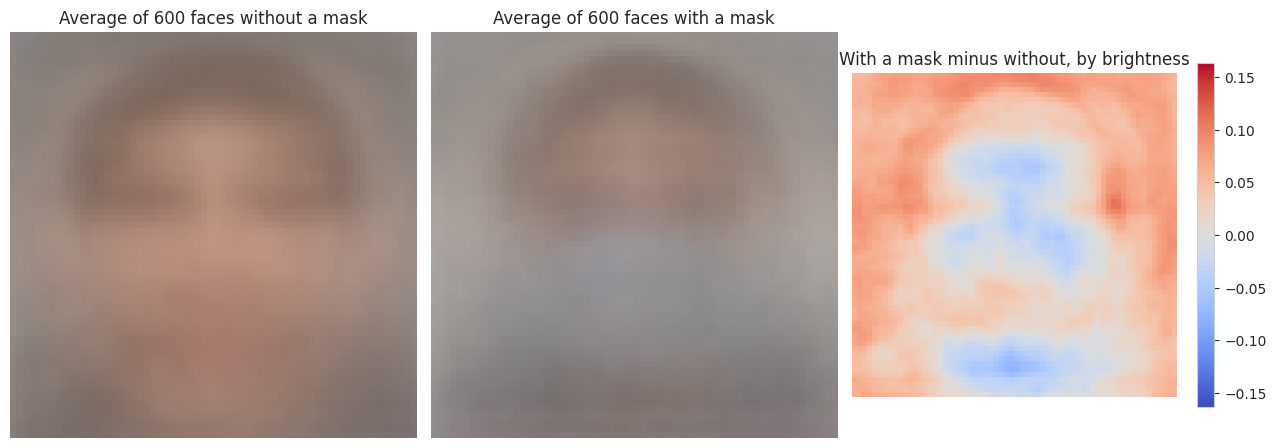

              Upper half brightness  Lower half brightness  Lower minus upper
class                                                                        
without mask                 0.5042                  0.523             0.0189
with mask                    0.5470                  0.540            -0.0070


In [8]:
# The average face of each class, and the difference between the two averages
averages = {}
for folder in ['without_mask', 'with_mask']:
    chosen = mask[mask['folder'] == folder]['path'].sample(600, random_state=RANDOM_STATE)
    stack = np.stack([load_image(path) for path in chosen])
    averages[folder] = stack.mean(axis=0)

difference = averages['with_mask'] - averages['without_mask']
fig, axes = plt.subplots(1, 3, figsize=(13, 4.6))
axes[0].imshow(averages['without_mask'])
axes[0].set_title('Average of 600 faces without a mask')
axes[1].imshow(averages['with_mask'])
axes[1].set_title('Average of 600 faces with a mask')
picture = axes[2].imshow(difference.mean(axis=2), cmap='coolwarm',
                         vmin=-abs(difference).max(), vmax=abs(difference).max())
axes[2].set_title('With a mask minus without, by brightness')
plt.colorbar(picture, ax=axes[2], shrink=0.8)
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

# The same comparison as numbers: how bright each half of the picture is
halves = []
for folder in ['without_mask', 'with_mask']:
    image = averages[folder]
    half = image.shape[0] // 2
    halves.append({'class': folder.replace('_', ' '),
                   'Upper half brightness': round(float(image[:half].mean()), 4),
                   'Lower half brightness': round(float(image[half:].mean()), 4),
                   'Lower minus upper': round(float(image[half:].mean() - image[:half].mean()), 4)})
print(pd.DataFrame(halves).set_index('class'))

The first two panels average 600 photographs of each class pixel by pixel, so
everything that changes from one photograph to the next cancels out and only what
they have in common survives. The third panel subtracts one average from the other
in brightness, with red where the covered faces are brighter and blue where the
uncovered ones are, and the table underneath measures the same thing.

Averaging that many faces leaves a blurred oval in both panels, which is the face
itself, and the difference panel does not put the change where the domain argument
would have put it. The strongest blue, meaning covered faces are darker there, sits
over the eyes and the brows, with a second patch at the bottom edge of the frame,
while the region a mask actually occupies comes out close to zero because a light
mask and lit skin have similar brightness.

The table says the same and corrects the expectation. The upper half moves from
0.5042 brightness without a mask to 0.5470 with one, a gap of 0.0428, so it is not
the stable part. The lower minus upper figure goes from 0.0189 to -0.0070, a
difference of 0.0259, which is the smaller of the two.

That is a limit of the measurement rather than a detail worth glossing over. A
single average brightness cannot tell a white mask from a black one and the two
push the number in opposite directions, so averaging thousands of faces flattens
the signal it was meant to show. The two half means stay in the description because
they cost three numbers each, and what decides whether colour is worth anything is
the comparison of the two halves of the description in the model section.

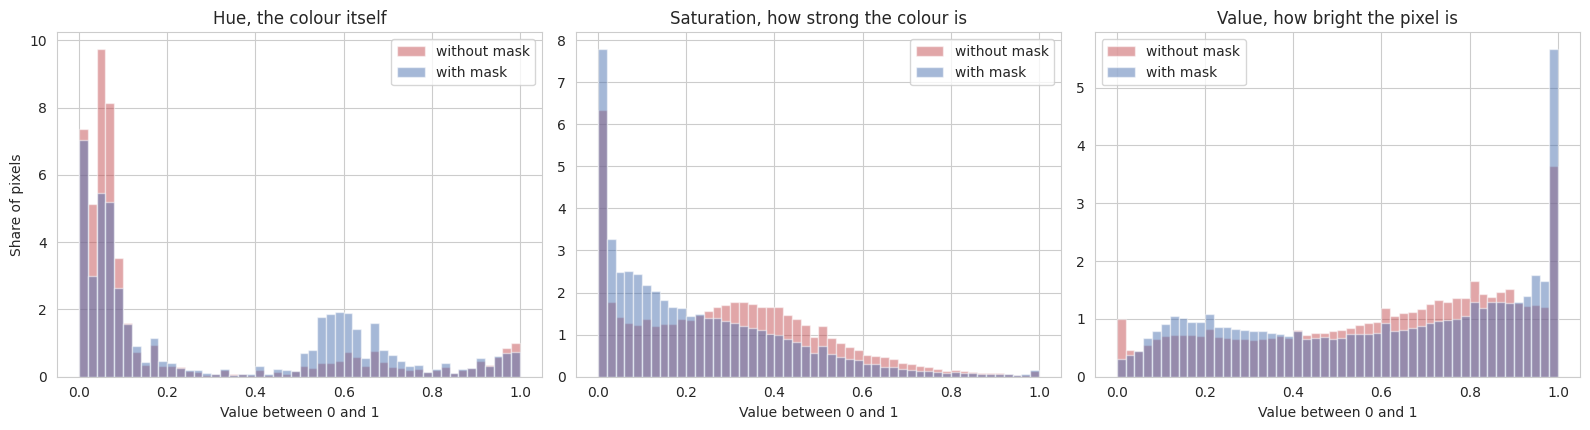

            without mask  with mask  Difference
Hue               0.2090     0.3161      0.1071
Saturation        0.2928     0.2198     -0.0730
Value             0.6014     0.6012     -0.0002


In [9]:
# The colour of the two classes, measured on 600 images of each: the spread of
# saturation and of brightness, which is where a mask shows up
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
channel_names = ['Hue, the colour itself', 'Saturation, how strong the colour is',
                 'Value, how bright the pixel is']
palette = {'without_mask': '#c44e52', 'with_mask': '#4c72b0'}

samples = {}
for folder in ['without_mask', 'with_mask']:
    chosen = mask[mask['folder'] == folder]['path'].sample(600, random_state=RANDOM_STATE)
    samples[folder] = np.stack([rgb2hsv(load_image(path)) for path in chosen])

for channel in range(3):
    for folder in ['without_mask', 'with_mask']:
        values = samples[folder][:, :, :, channel].ravel()
        axes[channel].hist(values, bins=50, range=(0, 1), density=True, alpha=0.5,
                           label=folder.replace('_', ' '), color=palette[folder])
    axes[channel].set_title(channel_names[channel])
    axes[channel].set_xlabel('Value between 0 and 1')
    axes[channel].legend()
axes[0].set_ylabel('Share of pixels')
plt.tight_layout()
plt.show()

# The same three channels as one number each per class
summary = pd.DataFrame({
    folder.replace('_', ' '): [samples[folder][:, :, :, c].mean() for c in range(3)]
    for folder in ['without_mask', 'with_mask']}, index=['Hue', 'Saturation', 'Value']).round(4)
summary['Difference'] = (summary['with mask'] - summary['without mask']).round(4)
print(summary)

The three histograms count pixels rather than images. The horizontal axis of each
one is the value of one HSV channel, from 0 to 1, and the height of a bar is the
share of the pixels of that class that fall in the bar, with the two classes drawn
on top of each other so the overlap is visible. The table under the plots reduces
each channel to its mean per class and prints the difference.

Most of the area is overlap, which is expected: both classes are photographs of
people, so skin, hair, clothing and background fill all three channels in much the
same way. But the parts that do not overlap are larger than a general argument
about masks coming in every colour would predict.

The hue plot carries a broad bump between 0.5 and 0.7 that belongs almost entirely
to the covered class. That band is blue and cyan, the colour of the surgical mask
that dominates this collection, and it moves the mean hue from 0.2090 to 0.3161, a
difference of 0.1071. The saturation plot shows the second signal, a much taller
spike at 0 for the covered class, and a pixel with no saturation is grey or white,
which is what a white mask contributes. The value plot agrees from the other side,
with the covered class piling up at 1, the brightest possible pixel. Together they
pull the mean saturation from 0.2928 down to 0.2198.

So colour is not the weak half it might be assumed to be, at least not in this
collection, and that is a property of this dataset rather than of the problem. The
model comparison later puts an accuracy on it instead of leaving it as an
impression.

In [10]:
# Every image is turned into its row of numbers. The result is kept in a file so
# that running the notebook a second time does not repeat the work
if os.path.exists(FEATURE_CACHE):
    stored = np.load(FEATURE_CACHE)
    X, y = stored['X'], stored['y']
    print('Features read back from', FEATURE_CACHE)
else:
    start = time.time()
    rows = np.empty((len(mask), HOG_LENGTH + COLOR_LENGTH), dtype=np.float32)
    for position, path in enumerate(mask['path']):
        rows[position] = describe_image(load_image(path))
        if (position + 1) % 1000 == 0:
            print('  %d of %d images described' % (position + 1, len(mask)))
    X = rows
    y = mask['label'].to_numpy()
    np.savez_compressed(FEATURE_CACHE, X=X, y=y)
    print('Described %d images in %.1f seconds.' % (len(mask), time.time() - start))

print()
print('Shape of the table the model reads:', X.shape)
print('Images with a mask:', int((y == 1).sum()), ' without:', int((y == 0).sum()))
print('Smallest and largest number in the table:', round(float(X.min()), 4),
      round(float(X.max()), 4))

  1000 of 7553 images described
  2000 of 7553 images described
  3000 of 7553 images described
  4000 of 7553 images described
  5000 of 7553 images described
  6000 of 7553 images described


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


  7000 of 7553 images described
Described 7553 images in 51.6 seconds.

Shape of the table the model reads: (7553, 1821)
Images with a mask: 3725  without: 3828
Smallest and largest number in the table: -0.6257 1.0


The cell describes every one of the 7553 photographs and reports how long it took,
then prints the shape of the table it produced, 7553 rows by 1821 columns. Each row
is one image and each column one measurement, so from here on the images are gone
and only this table is used.

The result is saved to a file, which is why the cell prints a different message
when the notebook is run twice. That is a convenience and not a modelling decision,
and it is tied to the settings at the top of the notebook: changing the image size
or the HOG parameters would need the file deleted, since the cached table would no
longer match the code.

The extremes printed at the end, -0.6257 and 1.0, say where each part of the
description lives. Nothing in the shape half or in the histograms can be negative,
since they are magnitudes and shares, so the negative end comes from the three
columns that subtract the upper half of the picture from the lower one, and the
upper end is a share of pixels in a single histogram bin, which happens when a
photograph is nearly all one colour.

No column is written in a wildly different unit from the others, which is a milder
version of the scaling problem than a raw dataset usually presents. It is not the
same as the columns being comparable, though, and the cell before the model
measures how unequal they still are.

Share of the variation kept by the two axes: [0.081 0.045]  total: 0.126


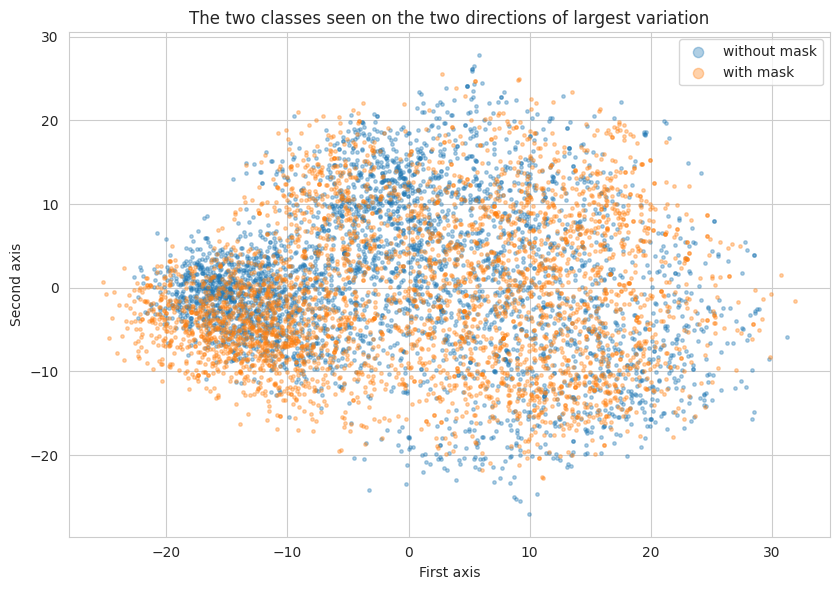

In [11]:
# The whole description compressed to two axes, only to look at it
projection = PCA(n_components=2, random_state=RANDOM_STATE)
coordinates = projection.fit_transform(StandardScaler().fit_transform(X))
print('Share of the variation kept by the two axes:',
      projection.explained_variance_ratio_.round(3),
      ' total:', round(projection.explained_variance_ratio_.sum(), 3))

plt.figure(figsize=(8.5, 6))
for label in [0, 1]:
    chosen = y == label
    plt.scatter(coordinates[chosen, 0], coordinates[chosen, 1], s=6, alpha=0.35,
                label=CLASS_NAMES[label])
plt.xlabel('First axis')
plt.ylabel('Second axis')
plt.title('The two classes seen on the two directions of largest variation')
plt.legend(markerscale=3)
plt.tight_layout()
plt.show()

The plot cannot show 1821 dimensions, so it compresses them to the two directions
along which the images differ the most and draws every photograph as a dot on those
two axes, coloured by its true class. The printed share says how much of the total
variation those two directions keep, and everything outside them is missing from
the picture.

Two points have to be made about how to read it. The axes are not features of the
problem, they are mixtures of all 1821 columns chosen for spread rather than for
usefulness, so a direction along which the classes separate may well have been left
out. And the share of variation kept here is 8.1 and 4.5 percent, 12.6 percent
together, so seven eighths of the variation is not in the drawing and it can only
be read as a hint.

Even so, the two colours are not spread at random. They form overlapping clouds
whose centres sit apart, which says the description does carry information about
the class, and the size of the overlap in the picture is an upper bound on how hard
the problem looks rather than on how hard it is. A boundary that is hopeless in two
dimensions can be comfortable in 1821, which is precisely the situation an SVM with
a radial kernel is built for.

In [12]:
# Three quarters to learn from and one quarter to be judged on, keeping the same
# share of the two classes on both sides. The split is made on the positions of
# the rows, so that a test image can be traced back to its file later
positions = np.arange(len(X))
train_index, test_index = train_test_split(
    positions, test_size=0.25, random_state=RANDOM_STATE, stratify=y)
X_train, X_test = X[train_index], X[test_index]
y_train, y_test = y[train_index], y[test_index]

print('Training images:', len(X_train), ' Test images:', len(X_test))
print()
print(pd.DataFrame({'Training': pd.Series(y_train).value_counts().sort_index(),
                    'Test': pd.Series(y_test).value_counts().sort_index()},
                   index=[0, 1]).rename(index=CLASS_NAMES))

# The floor of the evaluation: what answering the larger class every time scores
majority = pd.Series(y_test).value_counts(normalize=True).max()
print()
print('Accuracy of always answering the larger class:', round(float(majority), 4))

Training images: 5664  Test images: 1889

              Training  Test
without mask      2871   957
with mask         2793   932

Accuracy of always answering the larger class: 0.5066


The split leaves 5664 photographs to learn from and 1889 to be judged on, with 2871
and 957 uncovered faces against 2793 and 932 covered ones, so the two classes keep
their share on both sides. The stratification is what makes the test figures
comparable to the training ones, since without it the quarter set aside could end
up with a different mix and the accuracy would partly measure the split.

The last line is the number every result in this notebook has to beat. Answering
the larger class to every test photograph scores 0.5066 without looking at the
image, so it is the floor rather than a result, and with an almost even split that
floor is close to tossing a coin, which is the most demanding version of this
check.

The test images are not touched again until the evaluation section. Everything that
follows, the choice of kernel, the choice of the penalty and the comparison between
the two halves of the description, is decided by cross validation inside the
training set, which means splitting the training images into folds, fitting on some
and measuring on the rest. Using the test set for those decisions would turn it
into a second training set and its score into a report on the choices made rather
than on the model.

## Machine Learning Model (CRISP-DM 4: Modeling)

### How a Support Vector Machine decides

An SVM separates the two classes with a boundary, and among all the boundaries
that separate the training data it looks for the one that leaves the widest empty
corridor on either side. The images that end up sitting on the edge of that
corridor are the support vectors, and they are the only ones that define the
boundary: moving an image that lies well inside its own side changes nothing at
all, while moving one of the support vectors moves the whole boundary. This is
why an SVM is described as a model decided by its difficult cases.

Real data rarely allows a corridor with nothing inside it, so the model is given
a penalty, called C, for every image that falls on the wrong side or inside the
corridor. A small C buys a wide corridor at the price of tolerating mistakes on
the training images, and a large C insists on getting the training images right
even if the corridor becomes narrow and follows every irregularity of the data.
The first choice is therefore a trade between a boundary with room to spare and a
boundary that fits the training set too closely to generalise.

The second choice is the kernel. A linear kernel puts a flat boundary through the
1821 dimensional space. A radial kernel measures how close two images are to each
other and lets the boundary curve around groups of them, which is what is needed
when a class is not one blob but several, as here where masks of different
colours and faces at different angles form separate regions.

Because a radial kernel is built on distances between images, every column
contributes to that distance in proportion to how much it varies, so the columns
have to be brought to a common scale first. The next cell measures how unequal
they are before that is done.

In [13]:
# A radial kernel reads the distance between two images, and a distance is the
# sum over the columns, so each column weighs as much as it varies. This is that
# weight for the two halves of the description, before and after scaling
variances = X.var(axis=0)
hog_share = variances[:HOG_LENGTH].sum() / variances.sum() * 100
color_share = variances[HOG_LENGTH:].sum() / variances.sum() * 100
print('Columns in the shape half:', HOG_LENGTH,
      ' weight in a raw distance: %.2f %%' % hog_share)
print('Columns in the colour half:', COLOR_LENGTH,
      ' weight in a raw distance: %.2f %%' % color_share)
print()

# The ten columns that would dominate a raw distance
ranking = pd.DataFrame({
    'column': np.arange(len(variances)),
    'half': np.where(np.arange(len(variances)) < HOG_LENGTH, 'shape', 'colour'),
    'variance': variances,
    'weight %': variances / variances.sum() * 100}).sort_values('variance', ascending=False)
print('The ten columns with the largest weight in a raw distance:')
print(ranking.head(10).round(5).to_string(index=False))
print()
print('Weight of one column after scaling: %.4f %%' % (100 / len(variances)))

Columns in the shape half: 1764  weight in a raw distance: 97.50 %
Columns in the colour half: 57  weight in a raw distance: 2.50 %

The ten columns with the largest weight in a raw distance:
 column   half  variance  weight %
   1764 colour   0.05699   0.24425
   1780 colour   0.05496   0.23557
   1765 colour   0.03951   0.16934
     27  shape   0.03666   0.15713
   1811 colour   0.03258   0.13964
     28  shape   0.03247   0.13915
   1815 colour   0.03242   0.13897
    242  shape   0.03228   0.13834
    241  shape   0.03208   0.13750
   1817 colour   0.03183   0.13644

Weight of one column after scaling: 0.0549 %


The printout is the argument for scaling and it also says how strong that argument
is here.

The shape half takes 97.50 percent of the variation and the colour half 2.50
percent. Since the shape half has 1764 of the 1821 columns, that is 96.9 percent of
the columns carrying 97.5 percent of the weight, so as blocks they are close to
proportional and neither one would drown the other by sheer bulk.

The listing of individual columns is where the imbalance actually lives. Six of the
ten heaviest columns are colour columns, and the top two, columns 1764 and 1780,
carry 0.244 and 0.236 percent of a raw distance each. Those are the mean red of the
upper half of the picture and one of the half difference columns, quantities that
vary from photograph to photograph far more than any single gradient bin does.
Against them, one column after standardising weighs 0.0549 percent, so the heaviest
raw column counts about four and a half times what an average column should.

Standardising means subtracting the mean of a column and dividing by its standard
deviation, so that every column arrives at the distance with equal say. It is done
inside a pipeline rather than on the whole table, and the reason is not tidiness.
Fitting the scaler on all the data would let the mean and the standard deviation of
the test images influence the transformation applied to the training images, which
is information the model is not supposed to have. Inside a pipeline the scaler is
refitted on each training fold and applied to the held out fold, which is the
honest version of the same operation.

In [14]:
# Cross validation used for every comparison in this section. Three folds rather
# than five because an SVM on this many columns is slow, and the comparisons here
# only need to rank options
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

# The comparisons run on a stratified sample of the training images. Fitting an
# SVM costs more than the square of the number of images, so a search over the
# full training set would take hours while the ranking it produces is the same
SEARCH_SIZE = 2500
search_index, _ = train_test_split(np.arange(len(X_train)), train_size=SEARCH_SIZE,
                                   random_state=RANDOM_STATE, stratify=y_train)
X_search, y_search = X_train[search_index], y_train[search_index]
print('Images used for the search:', len(X_search))


def svm_pipeline(**settings):
    """A scaler and an SVM, so the scaler is refitted inside every fold."""
    return Pipeline([('scaler', StandardScaler()),
                     ('svc', SVC(random_state=RANDOM_STATE, **settings))])


# A flat boundary first, to see what a linear kernel can do here
start = time.time()
linear_scores = cross_val_score(svm_pipeline(kernel='linear', C=1),
                                X_search, y_search, cv=cv, scoring='accuracy')
print('Linear kernel, C = 1, accuracy: %.4f  (%.1f s)'
      % (linear_scores.mean(), time.time() - start))

# The same with a curved boundary
start = time.time()
rbf_scores = cross_val_score(svm_pipeline(kernel='rbf', C=1, gamma='scale'),
                             X_search, y_search, cv=cv, scoring='accuracy')
print('Radial kernel, C = 1, accuracy: %.4f  (%.1f s)'
      % (rbf_scores.mean(), time.time() - start))

Images used for the search: 2500
Linear kernel, C = 1, accuracy: 0.8092  (5.7 s)
Radial kernel, C = 1, accuracy: 0.8632  (12.9 s)


Both numbers are the average accuracy over three folds of the search sample, so
each one is measured on images the model did not see while it was being fitted, and
both are directly comparable to the floor of 0.5066.

The answer is clear. A flat boundary reaches 0.8092 and a curved one 0.8632 with
the same penalty, a gap of 5.4 points, so the two classes do not sit on either side
of a plane in this description. That is what a collection with masks of several
colours and faces at many angles should produce: each class is not one region but
several, and a radial kernel can wrap around groups of them while a linear kernel
has to cut through.

The times say the linear fit took 5.7 seconds and the radial one 12.9 for the same
three folds on 2500 images. Both are cheap here, and they are the reason the rest
of the search runs on a sample: the final model is fitted on 5664 images, and the
cost of an SVM grows faster than the number of images, so the same work on the full
training set would be several times slower for a ranking that would not change.

       Accuracy  F1 of the mask class
C                                    
0.1      0.7896                0.8161
1.0      0.8632                0.8635
10.0     0.8708                0.8707
100.0    0.8708                0.8707


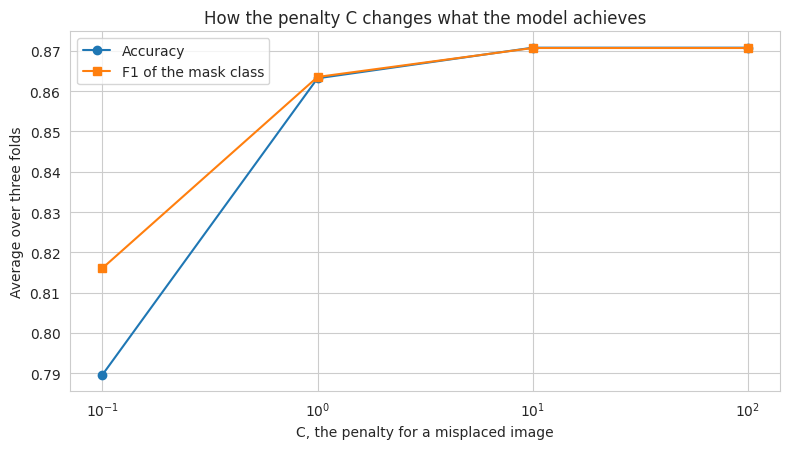

Penalty kept for the rest of the notebook: 10


In [15]:
# What the penalty C does, on a logarithmic scale because the useful values span
# several orders of magnitude
C_values = [0.1, 1, 10, 100]
accuracy_curve, f1_curve = [], []
for C in C_values:
    model = svm_pipeline(kernel='rbf', C=C, gamma='scale')
    # Both scores come out of the same fits, so the folds are run once per C
    folds = cross_validate(model, X_search, y_search, cv=cv,
                           scoring=['accuracy', 'f1'])
    accuracy_curve.append(folds['test_accuracy'].mean())
    f1_curve.append(folds['test_f1'].mean())

print(pd.DataFrame({'C': C_values,
                    'Accuracy': np.round(accuracy_curve, 4),
                    'F1 of the mask class': np.round(f1_curve, 4)}).set_index('C'))

plt.figure(figsize=(8, 4.6))
plt.plot(C_values, accuracy_curve, marker='o', label='Accuracy')
plt.plot(C_values, f1_curve, marker='s', label='F1 of the mask class')
plt.xscale('log')
plt.xlabel('C, the penalty for a misplaced image')
plt.ylabel('Average over three folds')
plt.title('How the penalty C changes what the model achieves')
plt.legend()
plt.tight_layout()
plt.show()

BEST_C = C_values[int(np.argmax(accuracy_curve))]
print('Penalty kept for the rest of the notebook:', BEST_C)

The curve is read from left to right as a move from a model that is too relaxed to
one that is strict enough. The horizontal axis is on a logarithmic scale, so each
step is a multiplication by ten, and the vertical axis is the average over the
three folds. Two lines are drawn because they can disagree: accuracy counts every
image once, and the F1 of the mask class combines how many covered faces were found
with how many of the faces called covered really were.

The two lines agree here and the shape is the textbook one. At C = 0.1 the model is
underfitted at 0.7896, because a mistake is so cheap that the widest corridor wins
and the boundary gives away the hard cases. At C = 1 it reaches 0.8632, at C = 10
it reaches 0.8708, and at C = 100 it stays at 0.8708, identical to four decimals.

So the useful range is a plateau rather than a peak, and C = 10 is kept as the
smallest value that reaches it. That flat top is a good sign: the result does not
depend on hitting one exact value, and since a larger C means a narrower corridor
and a longer fit, taking the left edge of the plateau buys the same accuracy with
more room to spare.

                  Columns  Accuracy  Spread over folds
Description                                           
shape only, HOG      1764    0.8500             0.0043
colour only            57    0.8084             0.0122
shape and colour     1821    0.8708             0.0070


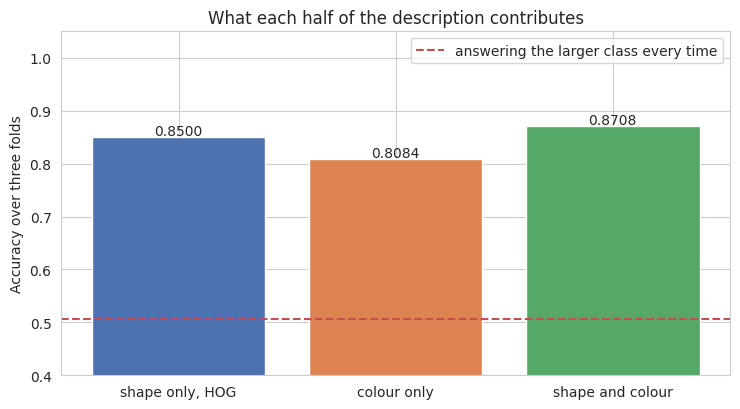

In [16]:
# What each half of the description is worth on its own, and what the two are
# worth together, under identical conditions
blocks = {'shape only, HOG': slice(0, HOG_LENGTH),
          'colour only': slice(HOG_LENGTH, None),
          'shape and colour': slice(0, None)}

comparison = []
for name, columns in blocks.items():
    model = svm_pipeline(kernel='rbf', C=BEST_C, gamma='scale')
    scores = cross_val_score(model, X_search[:, columns], y_search, cv=cv,
                             scoring='accuracy')
    comparison.append({'Description': name,
                       'Columns': X_search[:, columns].shape[1],
                       'Accuracy': round(scores.mean(), 4),
                       'Spread over folds': round(scores.std(), 4)})

comparison = pd.DataFrame(comparison).set_index('Description')
print(comparison)

plt.figure(figsize=(7.5, 4.2))
bars = plt.bar(comparison.index, comparison['Accuracy'], color=['#4c72b0', '#dd8452', '#55a868'])
for bar, value in zip(bars, comparison['Accuracy']):
    plt.text(bar.get_x() + bar.get_width() / 2, value + 0.005, '%.4f' % value, ha='center')
plt.ylim(0.4, 1.05)
plt.axhline(float(majority), color='#c44e52', linestyle='--',
            label='answering the larger class every time')
plt.ylabel('Accuracy over three folds')
plt.title('What each half of the description contributes')
plt.legend()
plt.tight_layout()
plt.show()

The three bars are the same model with the same penalty and the same folds, fitted
on three different sets of columns, so the only thing that changes between them is
what the model is allowed to see. The dashed line is the floor of 0.5066.

The shape half carries the problem, as the design of the description assumed. Alone
it reaches 0.8500, against 0.8084 for the colour half alone, a gap of 4.2 points,
and it does that with 1764 columns against 57. The colour half is not useless at
all, since 0.8084 with fifty seven numbers is far above the floor, and the reason is
the one the histograms showed: the masks in this collection are mostly blue or
white, so a few hue and saturation bins go a long way.

The two together reach 0.8708, which is 2.1 points above the shape half alone, so
the colour columns earn their place. They are not repeating what the gradients
already say, they are right about photographs the shape half gets wrong.

The spread over the folds is what says whether these gaps mean anything. It is
0.0043 for the shape half, 0.0122 for the colour half and 0.0070 for the two
together, so every gap discussed above is several times larger than the fold to
fold noise. The colour half is also the least stable of the three, which fits a
description that leans on the mask being a particular colour.

In [17]:
# The chosen model fitted on the whole training set
final_model = svm_pipeline(kernel='rbf', C=BEST_C, gamma='scale')
start = time.time()
final_model.fit(X_train, y_train)
print('Fitted on %d images in %.1f seconds.' % (len(X_train), time.time() - start))

# How many training images ended up holding the boundary
support = final_model.named_steps['svc'].n_support_
print()
print('Support vectors per class:', dict(zip([CLASS_NAMES[0], CLASS_NAMES[1]], support)))
print('Support vectors in total:', int(support.sum()),
      ' which is %.1f %% of the training images' % (100 * support.sum() / len(X_train)))

Fitted on 5664 images in 36.5 seconds.

Support vectors per class: {'without mask': np.int32(1619), 'with mask': np.int32(1647)}
Support vectors in total: 3266  which is 57.7 % of the training images


The model is now fitted on the full training set with the radial kernel and C = 10
chosen by cross validation. It took 36.5 seconds on 5664 images, against 12.9 for
three folds on 2500, which is the faster than linear growth in the number of images
showing up in practice.

The count of support vectors is a diagnostic rather than a formality. There are
3266 of them, 1619 from the uncovered class and 1647 from the covered one, which is
57.7 percent of the training images. That is a high share and it says the two
classes overlap heavily in this description: well over half of the training
photographs sit close enough to the boundary to help hold it, rather than a small
set of hard cases defining a comfortable frontier.

That number explains two things that appear later. It predicts that the test
accuracy will be good but not excellent, since a boundary held by more than half
the data is working hard. And it is the reason the saved model is large, because an
SVM has to store every support vector with all 1821 of its columns.

The balance between the two classes is the reassuring part. The support vectors
split almost evenly, so neither class is much harder to place than the other, and
the confusion matrix should come out roughly symmetric.

## Evaluation (CRISP-DM 5)

The test quarter has not been used for anything so far. It is read once here, and
the figures it produces are the only honest estimate in the notebook of how the
model would behave on photographs it has never seen.

In [18]:
# The model meets the test images for the first time
predictions = final_model.predict(X_test)

print('Accuracy on the test images: %.4f' % accuracy_score(y_test, predictions))
print('Accuracy of answering the larger class: %.4f' % majority)
print('F1 of the mask class: %.4f' % f1_score(y_test, predictions))
print()
print(classification_report(y_test, predictions,
                            target_names=[CLASS_NAMES[0], CLASS_NAMES[1]], digits=4))

Accuracy on the test images: 0.9052
Accuracy of answering the larger class: 0.5066
F1 of the mask class: 0.9030

              precision    recall  f1-score   support

without mask     0.8986    0.9164    0.9074       957
   with mask     0.9124    0.8938    0.9030       932

    accuracy                         0.9052      1889
   macro avg     0.9055    0.9051    0.9052      1889
weighted avg     0.9054    0.9052    0.9052      1889



The report has one row per class and four columns. Precision is the share of the
photographs the model called that class which really are that class, so it answers
how much a given answer can be trusted. Recall is the share of the photographs that
really are that class which the model found. F1 combines the two, and support is
how many test photographs the row is computed on.

The model reaches 0.9052 on the 1889 test photographs against a floor of 0.5066, so
it clears guessing by nearly 40 points, and the F1 of the mask class is 0.9030. The
two classes come out close but not identical: recall 0.9164 on the uncovered faces
and 0.8938 on the covered ones, precision 0.8986 and 0.9124.

The direction of that small asymmetry is the good one for this application, and it
is worth naming before the confusion matrix makes it concrete. The model is better
at finding uncovered faces than covered ones, which means it errs towards stopping
people rather than towards letting them through, and stopping a masked person is
the cheap mistake.

It also beats what the support vector count suggested. With 57.7 percent of the
training images holding the boundary the classes clearly overlap, and 0.9052 on
unseen photographs is a good result from a description of 1821 numbers that never
locates the face in the frame.

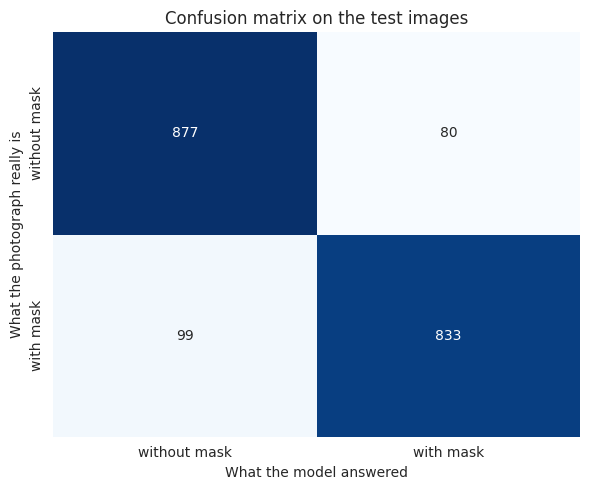

Uncovered faces admitted as covered: 80 out of 957
Covered faces stopped as uncovered: 99 out of 932


In [19]:
# Where the mistakes fall
matrix = confusion_matrix(y_test, predictions)
plt.figure(figsize=(6, 5))
sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=[CLASS_NAMES[0], CLASS_NAMES[1]],
            yticklabels=[CLASS_NAMES[0], CLASS_NAMES[1]])
plt.xlabel('What the model answered')
plt.ylabel('What the photograph really is')
plt.title('Confusion matrix on the test images')
plt.tight_layout()
plt.show()

# The two mistakes named, since they do not cost the same
uncovered_as_covered = int(matrix[0, 1])
covered_as_uncovered = int(matrix[1, 0])
print('Uncovered faces admitted as covered:', uncovered_as_covered,
      'out of', int(matrix[0].sum()))
print('Covered faces stopped as uncovered:', covered_as_uncovered,
      'out of', int(matrix[1].sum()))

The matrix has the true class down the rows and the answer of the model across the
columns, so the diagonal holds the photographs that were classified correctly and
everything off the diagonal is a mistake. The cell above the diagonal counts
uncovered faces called covered and the cell below it counts covered faces called
uncovered.

The two numbers printed under the plot separate the two mistakes because they do
not cost the same, and here they fall the right way round. The model admitted 80
uncovered faces of 957 as covered and stopped 99 covered faces of 932 as uncovered.
So the expensive failure, an uncovered face let through, is the less frequent of
the two, at about one uncovered face in twelve.

That balance is a property of where the boundary sits rather than of the data,
since the two classes are the same size, and it is not something the accuracy of
0.9052 would ever reveal, because accuracy adds both cells together as if they were
interchangeable. The next cell shows how much further the balance could be pushed.

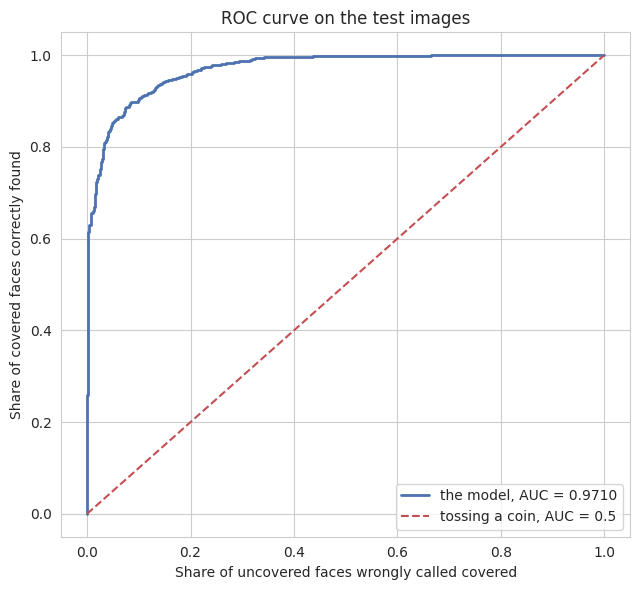

Area under the curve: 0.9710


In [20]:
# The ROC curve, which reads the model at every possible threshold rather than at
# the one it uses by default
scores = final_model.decision_function(X_test)
false_rate, true_rate, thresholds = roc_curve(y_test, scores)
area = roc_auc_score(y_test, scores)

plt.figure(figsize=(6.5, 6))
plt.plot(false_rate, true_rate, color='#4c72b0', linewidth=2,
         label='the model, AUC = %.4f' % area)
plt.plot([0, 1], [0, 1], color='#c44e52', linestyle='--', label='tossing a coin, AUC = 0.5')
plt.xlabel('Share of uncovered faces wrongly called covered')
plt.ylabel('Share of covered faces correctly found')
plt.title('ROC curve on the test images')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

print('Area under the curve: %.4f' % area)

The curve is built by walking a threshold across the score the model gives each
photograph, from a setting that calls everything uncovered to one that calls
everything covered, and plotting at each step how many covered faces are found
against how many uncovered ones are wrongly let through. The diagonal is what
answering at random achieves, and the ideal is the top left corner.

The area under the curve summarises this in one number that does not depend on the
threshold chosen. It runs from 0.5, meaning the model does not distinguish the
classes at all, to 1, meaning perfect separation, and it can be read as the
probability that a randomly chosen covered face receives a higher score than a
randomly chosen uncovered one.

Here it is 0.9710, noticeably above the accuracy of 0.9052, and that gap is the
useful part. It says the model ranks the photographs better than its decisions
suggest, so the ordering is good and the default threshold, the sign of the decision
function, is simply not where this application should read it.

The curve also says what the model could do rather than only what it does. A point
further left than the current operating point is a stricter setting, one that lets
fewer than the current 80 uncovered faces through at the price of stopping more than
the current 99 masked people, and the curve is steep near the corner, so the first
part of that trade is cheap.

Mistakes on the test set: 179 out of 1889


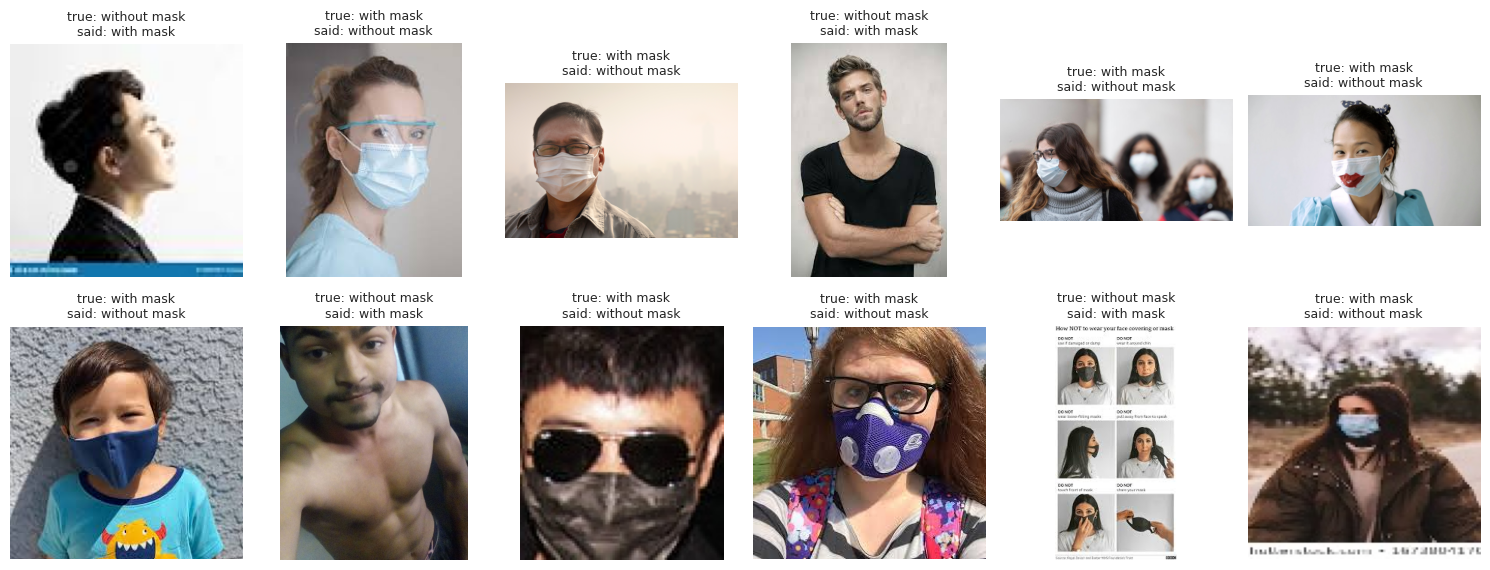

In [21]:
# The faces the model got wrong, twelve of them with what it answered
wrong = np.flatnonzero(predictions != y_test)
print('Mistakes on the test set:', len(wrong), 'out of', len(y_test))

if len(wrong) > 0:
    shown = wrong[:12]
    columns = 6
    rows_needed = int(np.ceil(len(shown) / columns))
    fig, axes = plt.subplots(rows_needed, columns, figsize=(15, 2.9 * rows_needed))
    for ax, position in zip(np.ravel(axes), shown):
        original = mask.iloc[test_index[position]]
        with Image.open(original['path']) as handle:
            ax.imshow(handle.convert('RGB'))
        ax.set_title('true: %s\nsaid: %s' % (CLASS_NAMES[y_test[position]],
                                             CLASS_NAMES[predictions[position]]),
                     fontsize=9)
        ax.axis('off')
    for ax in np.ravel(axes)[len(shown):]:
        ax.axis('off')
    plt.tight_layout()
    plt.show()

These are twelve of the 179 photographs the model got wrong out of 1889, each
labelled with what it really is and what the model answered. They are worth looking
at because a mistake made by a model that is doing something sensible looks
different from a mistake made by a model that has learned the wrong thing, and here
the errors have a clear pattern.

Nine of the twelve are covered faces called uncovered, and the masks in them are
almost never the blue or white surgical mask that dominates the collection. There
is a navy blue mask on a child, a black cloth mask worn with sunglasses, a purple
mask with a valve, a blue mask on a face far from the camera. That is the colour
half of the description showing its limit exactly where the exploration predicted:
it learned that masks are blue or white, so a mask of another colour costs the model
its second source of evidence and it has to decide on shape alone.

The rest are the failures of reading a whole frame instead of a face. One is a face
in profile with a watermark bar across the bottom, one is a crowd where three
people wear masks at different distances, one is a printed sheet of small
instructional photographs showing how not to wear a mask, which is a grid of faces
rather than a face.

All of these are limits of the description rather than of the SVM. Detecting and
cropping the face before describing it would fix the framing failures, and the
colour failures would need a collection with a wider variety of masks, since no
setting of C can invent evidence that the description does not carry.

Saved to mask_svm_hog_color.joblib (24.8 MB)


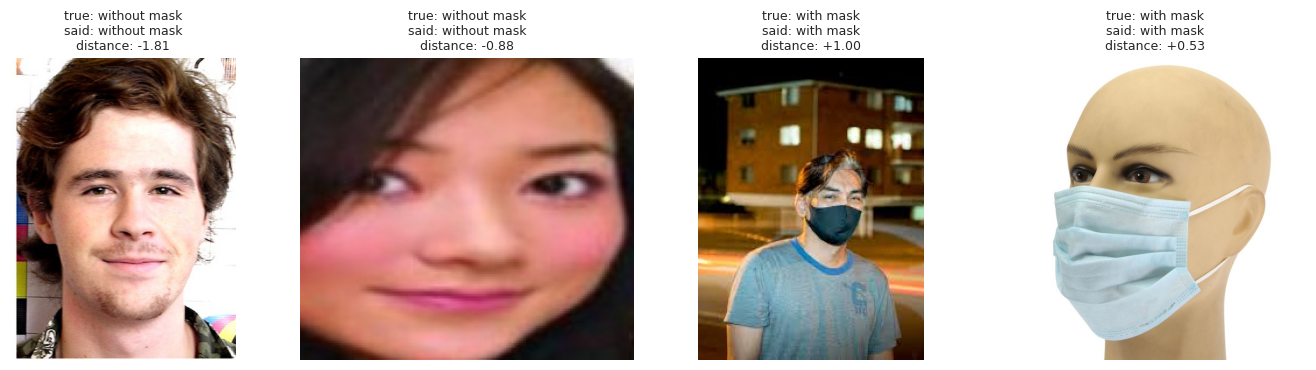

In [22]:
# The model is saved with everything it needs, since the scaler is part of the
# pipeline and a model without its scaler would read new images on the wrong scale
MODEL_FILE = 'mask_svm_hog_color.joblib'

# 3266 support vectors of 1821 columns each are tens of megabytes raw, so the file
# is compressed
joblib.dump(final_model, MODEL_FILE, compress=3)
print('Saved to', MODEL_FILE, '(%.1f MB)' % (os.path.getsize(MODEL_FILE) / 1024 ** 2))

# Read back and used on single photographs, which is how it would be deployed
restored = joblib.load(MODEL_FILE)


def classify_photograph(path, model):
    """Answer whether the face in one file is wearing a mask."""
    description = describe_image(load_image(path)).reshape(1, -1)
    answer = int(model.predict(description)[0])
    margin = float(model.decision_function(description)[0])
    return CLASS_NAMES[answer], margin


# Four test photographs, two of each class, classified one at a time
examples = list(test_index[y_test == 0][:2]) + list(test_index[y_test == 1][:2])
fig, axes = plt.subplots(1, 4, figsize=(14, 3.8))
for ax, position in zip(axes, examples):
    record = mask.iloc[position]
    answer, margin = classify_photograph(record['path'], restored)
    with Image.open(record['path']) as handle:
        ax.imshow(handle.convert('RGB'))
    ax.set_title('true: %s\nsaid: %s\ndistance: %+.2f'
                 % (record['folder'].replace('_', ' '), answer, margin), fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.show()

The saved file holds the scaler and the SVM together, which is the only correct way
to store this model. The numbers the SVM learned are meaningless applied to
unscaled columns, so a model saved without its scaler would give confident wrong
answers on new photographs rather than fail visibly.

It weighs 24.8 megabytes, and that is the price of the 3266 support vectors. The
arithmetic behind it does not depend on how the file is written: 3266 vectors of
1821 columns each, held as ordinary floating point numbers, are 45.4 megabytes of
raw values, and compressing them on the way to disk brings that down to the 24.8
printed here.

The model has to keep every one of those vectors because each prediction measures
the new photograph against all of them, so the size is also the cost of a single
answer. This is the practical consequence of the heavy overlap between the classes,
and it is worth stating plainly, since it is the one place where this model is
harder to ship than a simpler one.

The four examples show the deployed form of the model: one file in, one answer out,
going through exactly the same description the training images went through. The
distance printed under each face is the value of the decision function, which is how
far on its side of the corridor the photograph fell. Its sign is the answer and its
size is how far from the boundary the image sits, so a value close to zero marks a
photograph the model found borderline. That number is the one a real deployment
would threshold: given that the ROC curve is well above the accuracy, a camera that
must not let an uncovered face through would demand a comfortable positive distance
rather than accepting anything above zero.

## Results (CRISP-DM 6: Deployment)

The model takes a photograph of a face, brings it to 64 by 64 pixels, measures the
direction of the edges in every 8 by 8 square and the spread of the colours in HSV
plus how the lower half of the picture compares with the upper half, and separates
the two classes with a Support Vector Machine using a radial kernel and a penalty
of C = 10 on the 1821 numbers that result, with the columns standardised inside the
pipeline.

On the 1889 test photographs it reaches an accuracy of 0.9052 against a floor of
0.5066 for answering the larger class, an F1 of 0.9030 on the mask class and an area
under the ROC curve of 0.9710. It recognises 0.8938 of the covered faces and 0.9164
of the uncovered ones, and it makes 179 mistakes in total.

The choices behind that were all decided by cross validation inside the training
set. A linear kernel reaches 0.8092 against 0.8632 for a radial one at the same
penalty, so a flat boundary is not enough for these classes and the 5.4 point gap is
the evidence. The penalty reaches a plateau at C = 10 with 0.8708 and stays there at
C = 100, so the smallest value on the plateau was kept. The description was tested
in three pieces: the shape half alone scores 0.8500, the colour half alone 0.8084,
and the two together 0.8708, with fold to fold spreads of 0.0043, 0.0122 and 0.0070,
so both halves earn their place and the gaps are several times larger than the
noise.

The model is held up by a lot of data. There are 3266 support vectors, 57.7 percent
of the training images, split almost evenly between the classes, which says the two
classes overlap heavily in this description rather than sitting apart with a few
hard cases at the frontier. That is also what makes the model heavy, since every
support vector is stored with all 1821 of its columns, which is 45.4 megabytes of
raw numbers and 24.8 on disk once compressed.

The failures are consistent and they are failures of the description. Nine of the
twelve mistakes examined are covered faces called uncovered, and their masks are
almost all a colour other than blue or white, which is the colour half of the
description meeting the limit the exploration predicted for it. The remaining ones
come from reading the whole frame rather than a face: a profile with a watermark
bar, a crowd with several masked people at different distances, a printed sheet of
small instructional photographs.

For the door camera described at the start the model is usable, and the balance of
its mistakes is the right one. It admitted 80 uncovered faces of 957 as covered
while stopping 99 covered faces of 932, so the expensive failure is the less
frequent one, about one uncovered face in twelve, and the cheap failure absorbs the
difference. The area under the curve of 0.9710 sits well above the accuracy, which
means the ranking is better than the decisions and that raising the threshold would
cut the 80 further at a cost the curve shows to be low near that point. Any real
installation should set that threshold from the cost of the two mistakes rather
than leaving it at the sign of the decision function.

The limitations are worth stating plainly. The description reads the whole
photograph rather than a detected face, which is where the framing failures come
from, and cropping to a detected face is the single change most likely to help. The
colour half rests on masks being blue or white in this particular collection and
already fails on darker ones, so it would degrade on a population wearing cloth
masks. The collection is web photographs rather than frames from one fixed camera,
so these numbers are optimistic for a real installation. The model is heavy for an
embedded device and it grows with the data, since more training images mean more
support vectors, and each prediction has to measure the new photograph against
every one of them. And a mask worn below the nose is not a class in
this dataset, so the model would answer covered for it, which for the purpose of the
camera is the wrong answer.